<a href="https://colab.research.google.com/github/keyvanmahmoudi/Data_Science_Course/blob/main/solutions/Session01_numpy_fundamentals_solutions.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

# پاسخ تمرین‌های جلسهٔ ۱: NumPy، پایهٔ محاسبات عددی در پایتون

این نوت‌بوک پاسخ پیشنهادی تمرین‌های انتهای [نوت‌بوک جلسه](../sessions/Session01_numpy_fundamentals.ipynb) است. قبل از دیدن پاسخ‌ها، خودتان تمرین‌ها را حل کنید؛ معمولاً بیش از یک راه‌حل درست وجود دارد.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### آماده‌سازی

کتابخانه‌ها و داده‌هایی که پاسخ‌ها به آن‌ها نیاز دارند:

</div>

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### تمرین ۱

آرایه‌ای از دمای ۳۰ روز (اعداد تصادفی نرمال با میانگین ۲۵ و انحراف معیار ۵) بسازید. تعداد روزهایی که دما بالای میانگین بوده و میانگین دمای آن روزها را حساب کنید.

</div>

In [2]:
temps = rng.normal(loc=25, scale=5, size=30).round(1)
above = temps > temps.mean()
print("mean temperature       :", temps.mean().round(2))
print("days above the mean    :", above.sum())
print("mean of those days     :", temps[above].mean().round(2))

mean temperature       : 25.08
days above the mean    : 16
mean of those days     : 28.01


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### تمرین ۲

بدون حلقه، جدول ضرب ۱ تا ۹ را به‌صورت یک ماتریس ۹×۹ بسازید. (راهنما: پخش یک آرایهٔ ستونی و یک آرایهٔ سطری)

</div>

In [3]:
n = np.arange(1, 10)
table = n[:, np.newaxis] * n          # (9, 1) * (9,) -> (9, 9)
print(table)

[[ 1  2  3  4  5  6  7  8  9]
 [ 2  4  6  8 10 12 14 16 18]
 [ 3  6  9 12 15 18 21 24 27]
 [ 4  8 12 16 20 24 28 32 36]
 [ 5 10 15 20 25 30 35 40 45]
 [ 6 12 18 24 30 36 42 48 54]
 [ 7 14 21 28 35 42 49 56 63]
 [ 8 16 24 32 40 48 56 64 72]
 [ 9 18 27 36 45 54 63 72 81]]


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### تمرین ۳

ماتریس `scores` بالا را طوری مقیاس کنید که هر ستون بین ۰ و ۱ قرار بگیرد (Min-Max Scaling).

</div>

In [4]:
scores = np.column_stack([
    rng.normal(15, 2, 5),
    rng.normal(70, 10, 5),
    rng.normal(4, 0.5, 5),
]).round(1)

col_min = scores.min(axis=0)
col_max = scores.max(axis=0)
scaled = (scores - col_min) / (col_max - col_min)
print(scores)
print(scaled.round(3))
print("min per column:", scaled.min(axis=0), " max per column:", scaled.max(axis=0))

[[19.3 81.3  4.4]
 [14.2 68.9  4.3]
 [14.  61.6  3.7]
 [13.4 61.8  4.1]
 [16.2 76.5  4.1]]
[[1.    1.    1.   ]
 [0.136 0.371 0.857]
 [0.102 0.    0.   ]
 [0.    0.01  0.571]
 [0.475 0.756 0.571]]
min per column: [0. 0. 0.]  max per column: [1. 1. 1.]


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### تمرین ۴

با `rng.integers` پرتاب دو تاس را ۱۰۰٬۰۰۰ بار شبیه‌سازی کنید و احتمال اینکه جمع دو تاس ۷ شود را تخمین بزنید. مقدار دقیق آن ۶/۱ است.

</div>

In [5]:
n = 100_000
rolls = rng.integers(1, 7, size=(n, 2))
p_seven = (rolls.sum(axis=1) == 7).mean()
print(f"simulated P(sum = 7) = {p_seven:.4f}   exact = {1 / 6:.4f}")

simulated P(sum = 7) = 0.1683   exact = 0.1667


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### تمرین ۵

در تصویر بالا، پیکسل‌های نیمهٔ پایین را تیره‌تر کنید (مقدارشان را نصف کنید) و نتیجه را نمایش دهید.

</div>

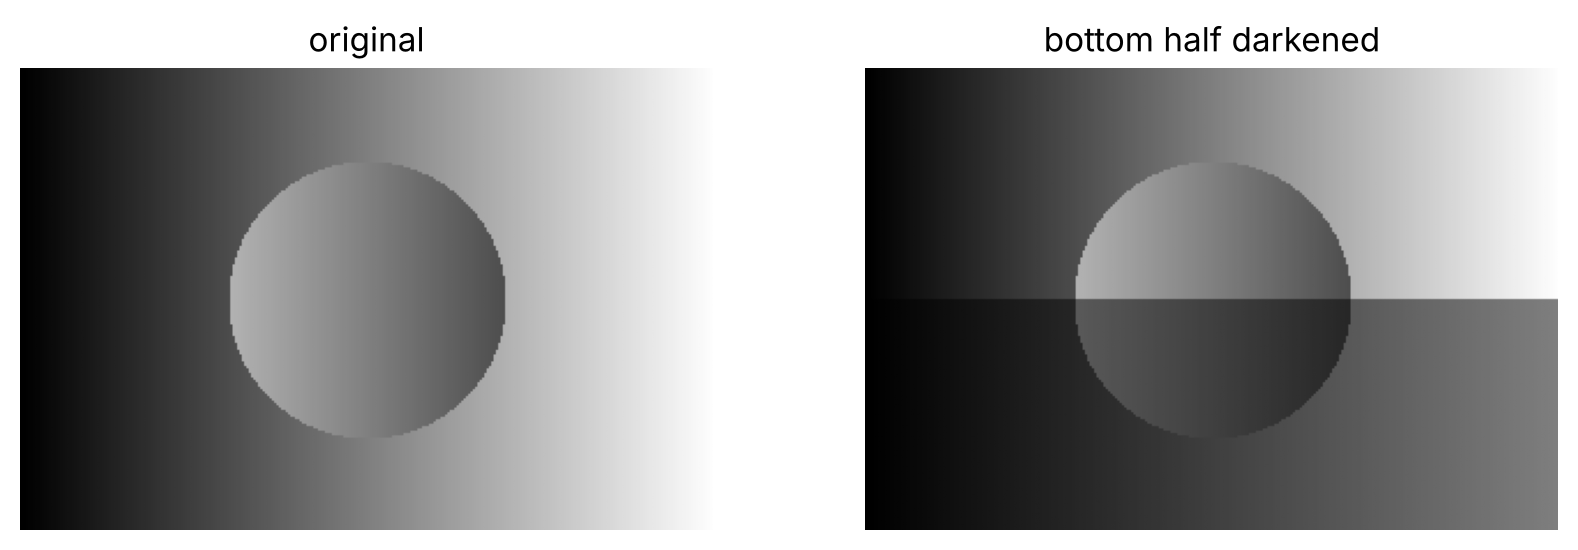

In [6]:
h, w = 200, 300
yy, xx = np.mgrid[0:h, 0:w]
img = (xx / w * 255).astype(np.uint8)
circle = (xx - 150) ** 2 + (yy - 100) ** 2 < 60 ** 2
img[circle] = 255 - img[circle]

darker = img.copy()
darker[h // 2:] = darker[h // 2:] // 2       # integer halving keeps the uint8 type

fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for ax, im, title in zip(axes, [img, darker], ["original", "bottom half darkened"]):
    ax.imshow(im, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")
plt.show()